# Medication Non-Adherence Risk | Medicare Part D

**Project:** Data engineering, refill-behavior analysis, and predictive-model development  
**Environment:** PyCharm · Python 3.11.3 · Jupyter · Docker/PostgreSQL 18.3  
**Source:** CMS DE-SynPUF Sample 1, 2008–2010 (synthetic Part D Prescription Drug Events)

## Business question

Can prescription dispensing history help identify beneficiaries who may be at risk of future medication non-adherence?

I started by establishing a reproducible data pipeline, then tested whether refill events contain enough longitudinal structure to support an adherence label. My proposed modeling setup uses **180 days of history** to predict **PDC below 80% in the subsequent 90 days**. This forward-looking target is a *project design*, not the complete CMS Star Ratings measure.

**Current boundary:** Source ingestion, data-quality checks, refill calculations, NDC9 exploration, and data-sufficiency assessment have been conducted. **Future PDC labels and machine learning models have not yet been built.**

**Interview flow:** Briefly establish the architecture, then focus on data-quality judgment, refill logic, medication grouping, what the evidence supports, and the path to a defensible model.

**References:** [CMS DE-SynPUF](https://www.cms.gov/data-research/statistics-trends-and-reports/medicare-claims-synthetic-public-use-files/cms-2008-2010-data-entrepreneurs-synthetic-public-use-file-de-synpuf) · [ResDAC Prescription Drug Events](https://www.resdac.org/cms-data/files/pde)


---
# Pre-section | Environment, connection, and data preparation

*Run this section before the analysis. I keep the infrastructure details here so the presentation can focus on methods and results. The raw PostgreSQL data remains untouched; staging transformations are views.*

### P0.1 Imports and interpreter verification

All notebook imports are centralized below. The project uses its existing Python `.venv`; no package installation is performed during the presentation.


In [1]:
import csv
import os
import sys
from getpass import getpass
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import psycopg
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

print(f"Python: {sys.version.split()[0]}")
print(f"Interpreter: {sys.executable}")
print(f"Pandas: {pd.__version__} | Scikit-Learn: {sklearn.__version__} | Psycopg: {psycopg.__version__}")


Python: 3.11.3
Interpreter: /Users/chi-chi/PycharmProjects/Medication_Non_Adherence_Prediction_Model/.venv/bin/python
Pandas: 3.1.1 | Scikit-Learn: 1.9.1 | Psycopg: 3.3.9


### P0.2 Connect to PostgreSQL

The Docker container is `data-sci`, exposed on `localhost:5432`; the database is `medicare_project`. I read the password at runtime instead of storing it in the notebook.


In [4]:
DB_USER = os.getenv("PGUSER", "postgres")
DB_HOST = os.getenv("PGHOST", "localhost")
DB_PORT = int(os.getenv("PGPORT", "5432"))
DB_NAME = os.getenv("PGDATABASE", "medicare_project")
DB_PASSWORD = os.getenv("POSTGRES_PASSWORD") or getpass("PostgreSQL password: ")

DATABASE_URL = URL.create(
    "postgresql+psycopg",
    username=DB_USER,
    password=DB_PASSWORD,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME,
)
engine = create_engine(DATABASE_URL, pool_pre_ping=True)

with engine.connect() as connection:
    db_info = dict(connection.execute(text("""
        SELECT current_database() AS database_name,
               current_user AS database_user,
               current_setting('server_version') AS server_version
    """)).mappings().one())

assert db_info["database_name"] == "medicare_project", db_info
print("Connected:", db_info)


Connected: {'database_name': 'medicare_project', 'database_user': 'postgres', 'server_version': '18.3 (Debian 18.3-1.pgdg13+1)'}


### P0.3 Identify and inspect the source CSV

I check the file path, schema, and first five rows without loading the full 405 MB source into memory. Identifiers are read as strings to preserve leading zeros.


In [8]:
csv_path = Path("data/raw/DE1_0_2008_to_2010_Prescription_Drug_Events_Sample_1.csv")
expected_columns = [
    "DESYNPUF_ID", "PDE_ID", "SRVC_DT", "PROD_SRVC_ID",
    "QTY_DSPNSD_NUM", "DAYS_SUPLY_NUM", "PTNT_PAY_AMT", "TOT_RX_CST_AMT",
]

if not csv_path.is_file():
    raise FileNotFoundError(f"CMS data not found at: {csv_path.resolve()}")
with csv_path.open("r", newline="", encoding="utf-8-sig") as file:
    actual_columns = next(csv.reader(file))
assert actual_columns == expected_columns, f"Unexpected CSV header: {actual_columns}"

df_sample = pd.read_csv(
    csv_path,
    nrows=5,
    dtype={"DESYNPUF_ID": "string", "PDE_ID": "string",
           "SRVC_DT": "string", "PROD_SRVC_ID": "string"},
)
print(f"CSV located: {csv_path} ({csv_path.stat().st_size / 1024**2:.2f} MB)")
print("Source columns:", list(df_sample.columns))
display(df_sample)


CSV located: data/raw/DE1_0_2008_to_2010_Prescription_Drug_Events_Sample_1.csv (405.31 MB)
Source columns: ['DESYNPUF_ID', 'PDE_ID', 'SRVC_DT', 'PROD_SRVC_ID', 'QTY_DSPNSD_NUM', 'DAYS_SUPLY_NUM', 'PTNT_PAY_AMT', 'TOT_RX_CST_AMT']


,DESYNPUF_ID,PDE_ID,SRVC_DT,PROD_SRVC_ID,QTY_DSPNSD_NUM,DAYS_SUPLY_NUM,PTNT_PAY_AMT,TOT_RX_CST_AMT
0,00013D2EFD8E45D1,233664490397622,20080103,00247037252,30.0,20,10.0,120.0
1,00013D2EFD8E45D1,233644490171972,20080105,00223039502,10.0,10,0.0,0.0
2,00013D2EFD8E45D1,233974489116848,20080109,00364724812,120.0,30,10.0,110.0
3,00013D2EFD8E45D1,233574491083209,20080123,00179180672,30.0,30,0.0,240.0
4,00013D2EFD8E45D1,233024491180571,20080124,58016005300,30.0,30,70.0,70.0


### P0.4 Raw schema and idempotent load

I preserve the original eight source columns in a raw table, adding an internal row ID. PostgreSQL `COPY` streams the file in chunks. If the raw table already contains rows, the import is **skipped** to avoid duplication. The load is not designed to silently append a second copy of the dataset.


In [9]:
# Create the raw schema and prescription table
with engine.begin() as connection:

    # Create a schema for raw CMS data
    connection.execute(text("""
        CREATE SCHEMA IF NOT EXISTS raw;
    """))

    # Create the prescription events table
    connection.execute(text("""
        CREATE TABLE IF NOT EXISTS raw.prescription_drug_events (
            source_row_id BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
            desynpuf_id TEXT,
            pde_id TEXT,
            srvc_dt TEXT,
            prod_srvc_id TEXT,
            qty_dspnsd_num TEXT,
            days_suply_num TEXT,
            ptnt_pay_amt TEXT,
            tot_rx_cst_amt TEXT
        );
    """))

print("Raw prescription events table created successfully!")


Raw prescription events table created successfully!


In [10]:
expected_columns = [
    "DESYNPUF_ID", "PDE_ID", "SRVC_DT", "PROD_SRVC_ID",
    "QTY_DSPNSD_NUM", "DAYS_SUPLY_NUM", "PTNT_PAY_AMT", "TOT_RX_CST_AMT",
]
assert csv_path.is_file(), f"Source file missing: {csv_path}"
with csv_path.open("r", newline="", encoding="utf-8-sig") as file:
    assert next(csv.reader(file)) == expected_columns, "Unexpected CSV header"

with engine.connect() as connection:
    existing_rows = connection.execute(
        text("SELECT COUNT(*) FROM raw.prescription_drug_events")
    ).scalar_one()

if existing_rows:
    print(f"Skipping COPY: raw table already contains {existing_rows:,} records.")
else:
    copy_sql = """
    COPY raw.prescription_drug_events (
        desynpuf_id, pde_id, srvc_dt, prod_srvc_id,
        qty_dspnsd_num, days_suply_num, ptnt_pay_amt, tot_rx_cst_amt
    ) FROM STDIN WITH (FORMAT CSV, HEADER TRUE)
    """
    start = perf_counter()
    db_connection = engine.raw_connection()
    try:
        with db_connection.cursor() as cursor:
            with cursor.copy(copy_sql) as copy:
                with csv_path.open("rb") as file:
                    while chunk := file.read(4 * 1024 * 1024):
                        copy.write(chunk)
        db_connection.commit()
        print(f"COPY complete in {perf_counter() - start:.1f} seconds")
    except Exception:
        db_connection.rollback()
        raise
    finally:
        db_connection.close()


Skipping COPY: raw table already contains 5,552,421 records.


### P0.5 Typed staging view

The staging view converts dates and numeric fields while **preserving `DAYS_SUPLY_NUM = 0`** in `days_supply_reported`. A separate Boolean flag indicates whether days supply is positive and within 1–999 for an *exploratory coverage calculation*. This is not a CMS claim-validity determination.

I use `CREATE OR REPLACE VIEW` with the existing column structure instead of dropping a view that later analysis objects may depend on.


In [11]:
# Step 3.7: Create the cleaned prescription data layer

with engine.begin() as connection:

    # 1. Create the staging schema
    connection.execute(text("""
        CREATE SCHEMA IF NOT EXISTS staging;
    """))

    # 2. Create or replace the staging view
    connection.execute(text("""
        CREATE OR REPLACE VIEW staging.prescription_drug_events AS

        SELECT
            -- Unique source record identifier
            source_row_id,

            -- Medicare beneficiary identifier
            desynpuf_id,

            -- Prescription event identifier
            pde_id,

            -- Convert prescription date from YYYYMMDD to DATE
            TO_DATE(
                NULLIF(srvc_dt, ''),
                'YYYYMMDD'
            ) AS service_date,

            -- Medication product identifier
            prod_srvc_id,

            -- Quantity dispensed
            NULLIF(qty_dspnsd_num, '')::NUMERIC
                AS quantity_dispensed,

            -- Preserve CMS days-supply values, including 0
            NULLIF(days_suply_num, '')::INTEGER
                AS days_supply_reported,

            -- Flag zero-day prescriptions
            (
                NULLIF(days_suply_num, '')::INTEGER = 0
            ) AS days_supply_is_zero,

            -- Flag records usable for PDC coverage calculations
            (
                NULLIF(days_suply_num, '')::INTEGER
                BETWEEN 1 AND 999
            ) AS pdc_coverage_eligible,

            -- Patient prescription payment
            NULLIF(ptnt_pay_amt, '')::NUMERIC
                AS patient_pay_amount,

            -- Total prescription cost
            NULLIF(tot_rx_cst_amt, '')::NUMERIC
                AS total_prescription_cost

        FROM raw.prescription_drug_events;
    """))

print("Staging prescription view created successfully!")
print("Original days-supply values preserved.")
print("PDC eligibility and zero-day flags added.")


Staging prescription view created successfully!
Original days-supply values preserved.
PDC eligibility and zero-day flags added.


### P0.6 Full-load verification

These checks reconcile raw and staging event counts, preserve the zero-day records, and validate beneficiary identifiers, dates, and numerical ranges. The displayed findings below reflect outputs from my prior completed run and should be refreshed if the underlying data changes.


In [12]:
verification_query = """
SELECT
    COUNT(*) AS total_prescriptions,
    COUNT(DISTINCT desynpuf_id) AS unique_beneficiaries,
    COUNT(*) FILTER (
        WHERE days_suply_num = '0'
    ) AS zero_day_prescriptions
FROM raw.prescription_drug_events;
"""

df_verification = pd.read_sql(
    verification_query,
    engine
)

display(df_verification)


,total_prescriptions,unique_beneficiaries,zero_day_prescriptions
0,5552421,99538,117726


In [13]:
sql_staging_check = """
SELECT
    COUNT(*) AS total_prescriptions,

    COUNT(*) FILTER (
        WHERE days_supply_is_zero
    ) AS zero_day_prescriptions,

    COUNT(*) FILTER (
        WHERE pdc_coverage_eligible
    ) AS pdc_eligible_prescriptions,

    COUNT(*) FILTER (
        WHERE NOT pdc_coverage_eligible
           OR pdc_coverage_eligible IS NULL
    ) AS pdc_ineligible_prescriptions

FROM staging.prescription_drug_events;
"""

df_staging_check = pd.read_sql(sql_staging_check, engine)

display(df_staging_check)


,total_prescriptions,zero_day_prescriptions,pdc_eligible_prescriptions,pdc_ineligible_prescriptions
0,5552421,117726,5434695,117726


In [14]:
sql_full_validation = """
SELECT
    COUNT(DISTINCT desynpuf_id) AS unique_beneficiaries,

    MIN(service_date) AS earliest_prescription,
    MAX(service_date) AS latest_prescription,

    COUNT(*) FILTER (
        WHERE service_date IS NULL
           OR service_date NOT BETWEEN
               DATE '2008-01-01' AND DATE '2010-12-31'
    ) AS invalid_dates,

    COUNT(*) FILTER (
        WHERE days_supply_reported IS NULL
           OR days_supply_reported < 0
           OR days_supply_reported > 999
    ) AS out_of_range_days_supply,

    COUNT(*) FILTER (
        WHERE prod_srvc_id IS NULL
           OR TRIM(prod_srvc_id) = ''
    ) AS missing_medication_ids,

    COUNT(*) FILTER (
        WHERE quantity_dispensed < 0
    ) AS negative_quantities

FROM staging.prescription_drug_events;
"""

df_validation = pd.read_sql(sql_full_validation, engine)

display(df_validation)


,unique_beneficiaries,earliest_prescription,latest_prescription,invalid_dates,out_of_range_days_supply,missing_medication_ids,negative_quantities
0,99538,2008-01-01,2010-12-31,0,0,0,0


In [16]:
raw_n = int(df_verification.loc[0, "total_prescriptions"])
staged_n = int(df_staging_check.loc[0, "total_prescriptions"])
raw_zero = int(df_verification.loc[0, "zero_day_prescriptions"])
staged_zero = int(df_staging_check.loc[0, "zero_day_prescriptions"])
assert raw_n == staged_n, (raw_n, staged_n)
assert raw_n == 5_552_421, f"Unexpected raw row count: {raw_n:,}; check import before proceeding"
assert raw_zero == staged_zero, (raw_zero, staged_zero)
assert int(df_staging_check.loc[0, "pdc_eligible_prescriptions"]) + staged_zero == staged_n
print(f"Setup verified: {raw_n:,} raw and staged events; {staged_zero:,} zero-day records preserved.")


Setup verified: 5,552,421 raw and staged events; 117,726 zero-day records preserved.


**Setup checkpoint (observed):** 5,552,421 prescription events; 99,538 beneficiaries in the full raw dataset; 117,726 zero-day records; 5,434,695 records reporting 1–999 days supplied. No out-of-range days supply, negative quantity, missing drug identifiers, or invalid service dates were found in the full staging checks.

**Speaking point:** “I used PostgreSQL to retain and validate the complete dataset. The notebook stays focused on analysis and machine learning, not the mechanics of moving five million records.”


---
# 1. Source quality | Defining usable coverage

**Question:** What can I reliably infer from the source fields?

I initially inspected 50,000 events and then investigated the entire raw table. The key distinction was between **a source value being allowed** and **that value supporting a coverage-duration calculation**.


In [17]:
# Initial quality screen of 50,000 prescription events

df_quality = pd.read_csv(
    csv_path,
    nrows=50_000,
    dtype={
        "DESYNPUF_ID": "string",
        "PDE_ID": "string",
        "SRVC_DT": "string",
        "PROD_SRVC_ID": "string",
    },
)
df_quality["SRVC_DT"] = pd.to_datetime(
    df_quality["SRVC_DT"], format="%Y%m%d", errors="coerce"
)

print("Rows:", len(df_quality))
print("Missing values:", int(df_quality.isna().sum().sum()))
print("Duplicate PDE IDs:", int(df_quality["PDE_ID"].duplicated().sum()))
print("Invalid dates:", int(df_quality["SRVC_DT"].isna().sum()))
print("Zero days supplied:", int(df_quality["DAYS_SUPLY_NUM"].eq(0).sum()))
print("Negative days supplied:", int(df_quality["DAYS_SUPLY_NUM"].lt(0).sum()))
print("Unique beneficiaries:", df_quality["DESYNPUF_ID"].nunique())
print("Date range:", df_quality["SRVC_DT"].min().date(), "to", df_quality["SRVC_DT"].max().date())
print("Median days supply:", df_quality["DAYS_SUPLY_NUM"].median())


Rows: 50000
Missing values: 0
Duplicate PDE IDs: 0
Invalid dates: 0
Zero days supplied: 998
Negative days supplied: 0
Unique beneficiaries: 954
Date range: 2008-01-01 to 2010-12-31
Median days supply: 30.0


#### Findings — Initial Data Quality Assessment

I began by examining the first 50,000 prescription events
to evaluate data structure and identify potential quality
issues before conducting analysis across the full dataset.

**Key findings:**

- No missing values, duplicate PDE identifiers, or
  invalid prescription dates were identified.
- The median prescription days supply was 30 days.
- 998 records (1.996%) reported zero days supplied.
- The records spanned the full 2008–2010 study period.

**Interpretation:**

Although zero days supplied initially appeared unusual,
CMS documentation identifies zero as an allowable value.
I therefore retained those records and investigated their
impact on medication coverage calculations.

Because this assessment used the first 50,000 records,
I treated the results as preliminary and subsequently
validated data quality across the full PostgreSQL dataset.


In [19]:
sql_zero_day_events = """
SELECT
    COUNT(*) AS total_zero_day_events,

    COUNT(*) FILTER (
        WHERE qty_dspnsd_num::NUMERIC > 0
    ) AS positive_quantity_events,

    COUNT(*) FILTER (
        WHERE tot_rx_cst_amt::NUMERIC > 0
    ) AS positive_cost_events

FROM raw.prescription_drug_events
WHERE days_suply_num::NUMERIC = 0;
"""

df_zero_supply = pd.read_sql(sql_zero_day_events, engine)

display(df_zero_supply)


,total_zero_day_events,positive_quantity_events,positive_cost_events
0,117726,101200,97467


#### Findings — Zero-Day Supply Investigation

Across the full dataset, I identified 117,726 prescription
events (2.12%) reporting zero days supplied.

Of these:
- 86.0% reported a positive dispensing quantity.
- 82.8% reported a positive prescription cost.

These findings reinforced the need to distinguish
valid source values from values suitable for
medication coverage calculations.

**Decision:** I preserved the original records and
introduced separate flags to identify zero-day events
and records with positive days supply.

This approach maintains data integrity while allowing
me to evaluate how uncertain coverage affects
downstream adherence calculations.



---
# 2. Refill timing | From SQL sequences to stockpiling

**Question:** Can I derive meaningful refill intervals from individual PDE records?

I started by matching exact product codes (`NDC11`) and using PostgreSQL `LAG()` to order fills. I then tested a concrete three-fill history before scaling any gap calculation.


In [25]:
sql_ndc11_repeats = """
SELECT
    desynpuf_id,
    prod_srvc_id,
    COUNT(*) AS total_fills,
    MIN(service_date) AS first_fill,
    MAX(service_date) AS last_fill

FROM staging.prescription_drug_events

WHERE pdc_coverage_eligible IS TRUE

GROUP BY
    desynpuf_id,
    prod_srvc_id

HAVING COUNT(*) >= 2

ORDER BY
    total_fills DESC,
    desynpuf_id,
    prod_srvc_id

"""

df_repeated_fills = pd.read_sql(sql_ndc11_repeats, engine)


# Summarize repeated prescriptions by NDC11
total_groups = len(df_repeated_fills)
three_plus = (df_repeated_fills["total_fills"] >= 3).sum()
max_fills = df_repeated_fills["total_fills"].max()

print("NDC11 Refill Analysis")
print("-" * 40)
print(f"Groups with 2+ fills: {total_groups:,}")
print(f"Groups with 3+ fills: {three_plus:,}")
print(f"Maximum fills per group: {max_fills}")

# Calculate the distribution
fill_distribution = (
    df_repeated_fills["total_fills"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Fills")
    .reset_index(name="Number of Groups")
)

print("\nDistribution of Repeated Fills:")
print(fill_distribution.to_string(index=False))



NDC11 Refill Analysis
----------------------------------------
Groups with 2+ fills: 3,213
Groups with 3+ fills: 7
Maximum fills per group: 3

Distribution of Repeated Fills:
 Number of Fills  Number of Groups
               2              3206
               3                 7


#### Findings — Prescription Refill Continuity (NDC11)

I grouped prescription events by beneficiary and the
full 11-digit National Drug Code (NDC) to identify
repeated fills of the same medication product.

**Key findings:**
- 3,213 beneficiary–product combinations had at least
  two prescription events.
- Only seven combinations contained three fills.
- No combination contained more than three fills.

**Interpretation:**

Repeated prescriptions with identical NDC11 identifiers
were uncommon in the synthetic dataset.

This raised an important modeling consideration:
grouping strictly by NDC11 may fragment refill histories
when the same medication is dispensed in different
package sizes.

I decided to investigate medication grouping at the
nine-digit product level before developing patient-level
adherence features.

**Limitation:** CMS DE-SynPUF drug identifiers have
been modified for disclosure protection, so repeated
product codes do not establish verified therapeutic
continuity.



In [26]:
# Select a beneficiary with three recorded fills
beneficiary_id = "76F99DA321757C69"
medication_id = "54868540600"

sql_three_fill_history = text("""
WITH refill_history AS (
    SELECT
        desynpuf_id,
        prod_srvc_id,
        service_date,
        days_supply_reported,

        LAG(service_date) OVER (
            PARTITION BY desynpuf_id, prod_srvc_id
            ORDER BY service_date, source_row_id
        ) AS previous_fill_date,

        LAG(days_supply_reported) OVER (
            PARTITION BY desynpuf_id, prod_srvc_id
            ORDER BY service_date, source_row_id
        ) AS previous_days_supply

    FROM staging.prescription_drug_events

    WHERE desynpuf_id = :beneficiary_id
      AND prod_srvc_id = :medication_id
      AND pdc_coverage_eligible IS TRUE
)

SELECT
    service_date,
    days_supply_reported,
    previous_fill_date,
    previous_days_supply,

    -- Calculate days between fills
    service_date - previous_fill_date
        AS days_between_fills,

    -- Expected next refill date
    previous_fill_date + previous_days_supply
        AS expected_refill_date,

    -- Calculate estimated refill gap
    CASE
        WHEN previous_fill_date IS NULL
        THEN NULL

        ELSE GREATEST(
            0,
            service_date -
            (previous_fill_date + previous_days_supply)
        )
    END AS refill_gap_days

FROM refill_history

ORDER BY service_date;
""")

df_three_fills = pd.read_sql(sql_three_fill_history,
    engine,
    params={
        "beneficiary_id": beneficiary_id,
        "medication_id": medication_id
    }
)

display(df_three_fills)


,service_date,days_supply_reported,previous_fill_date,previous_days_supply,days_between_fills,expected_refill_date,refill_gap_days
0,2008-01-14,90,None,NaN,NaN,None,NaN
1,2008-03-29,30,2008-01-14,90.0,75.0,2008-04-13,0.0
2,2008-05-07,30,2008-03-29,30.0,39.0,2008-04-28,9.0


**Finding — naive gaps:** In one sequence, the beneficiary filled **90 days on January 14, 2008**, **30 days on March 29**, and **30 days on May 7**. A simple comparison between consecutive fills produced a **9-day gap** before the third fill. That ignored medication remaining from the earlier 90-day supply.


In [28]:
# Select the columns needed for coverage calculations
df_stockpile = df_three_fills[
    ["service_date", "days_supply_reported"]
].copy()

# Ensure dates use the correct data type
df_stockpile["service_date"] = pd.to_datetime(
    df_stockpile["service_date"]
)

# Sort prescriptions chronologically
df_stockpile = df_stockpile.sort_values(
    "service_date"
).reset_index(drop=True)

# Track the date when medication supply runs out
coverage_end = None

results = []

for _, row in df_stockpile.iterrows():

    fill_date = row["service_date"]
    days_supply = int(row["days_supply_reported"])

    if coverage_end is None:
        # First prescription
        carryover_days = 0
        adjusted_gap = None
        coverage_start = fill_date

    else:
        # Days without supply before this fill
        adjusted_gap = max(
            0,
            (fill_date - coverage_end).days
        )

        # Unused medication from previous fills
        carryover_days = max(
            0,
            (coverage_end - fill_date).days
        )

        # Extend coverage when medication remains
        coverage_start = max(fill_date, coverage_end)

    # Update expected coverage end
    coverage_end = coverage_start + pd.Timedelta(
        days=days_supply
    )

    results.append({
        "fill_date": fill_date.date(),
        "days_supply": days_supply,
        "carryover_days": carryover_days,
        "adjusted_gap_days": adjusted_gap,
        "next_expected_refill": coverage_end.date()
    })

# Convert results into a DataFrame
df_adjusted_refills = pd.DataFrame(results)

display(df_adjusted_refills)


,fill_date,days_supply,carryover_days,adjusted_gap_days,next_expected_refill
0,2008-01-14,90,0,NaN,2008-04-13
1,2008-03-29,30,15,0.0,2008-05-13
2,2008-05-07,30,6,0.0,2008-06-12


#### Findings — Refill Gaps and Medication Stockpiling

I initially calculated refill gaps using the time between
consecutive prescriptions and the previous days supplied.

The initial calculation identified a 9-day gap for the
May 7, 2008 prescription.

However, the beneficiary had refilled 15 days early in
March, leaving medication available from the earlier fill.

After adjusting for unused medication carried forward:

- The March refill had 15 days of remaining supply.
- The May refill had 6 days of remaining supply.
- The estimated 9-day gap decreased to 0 days.

**Conclusion**

Accounting for medication stockpiling materially changed
the calculated refill gap. Without this adjustment, the
model could incorrectly interpret early refill behavior
as an interruption in medication availability.

I incorporated carryover into the exploratory calculation
to improve the accuracy of refill-timing features.

This remains a simplified same-product calculation and
does not establish actual medication consumption or
reproduce the full CMS PDC methodology.

---
# 3. Medication grouping | NDC11 versus NDC9

**Question:** Does removing the two package digits improve repeated-fill coverage?

I derived an NDC9 prefix and compared repeated product sequences. In the standard 11-digit NDC configuration, the last two digits identify the package; however, the **synthetic DE-SynPUF drug identifiers were modified**, so the grouping is an engineering hypothesis—not verified clinical equivalence.


In [29]:
# Create a staging view with an additional NDC9 column
with engine.begin() as connection:

    connection.execute(text("""
        CREATE OR REPLACE VIEW
        staging.prescription_drug_events_ndc9 AS

        SELECT
            *,

            -- Extract the first 9 digits of NDC11
            CASE
                WHEN TRIM(prod_srvc_id) ~ '^[0-9]{11}$'
                THEN LEFT(TRIM(prod_srvc_id), 9)
                ELSE NULL
            END AS ndc9_product_id

        FROM staging.prescription_drug_events;
    """))

print("NDC9 staging view created successfully!")


NDC9 staging view created successfully!


In [32]:
sql_ndc9_validation = """
SELECT
    desynpuf_id,
    prod_srvc_id,
    ndc9_product_id,
    RIGHT(prod_srvc_id, 2) AS package_code,
    service_date,
    days_supply_reported

FROM staging.prescription_drug_events_ndc9

WHERE desynpuf_id = '70E3B962B5448883'
  AND ndc9_product_id = '580160877'

ORDER BY service_date;
"""

df_ndc9_validation = pd.read_sql(
    sql_ndc9_validation,
    engine
)

display(df_ndc9_validation)

print("Total prescription events:", len(df_ndc9_validation))
print(
    "Distinct packaging codes:",
    df_ndc9_validation["package_code"].nunique()
)


,desynpuf_id,prod_srvc_id,ndc9_product_id,package_code,service_date,days_supply_reported
0,70E3B962B5448883,58016087704,580160877,04,2008-04-05,30
1,70E3B962B5448883,58016087732,580160877,32,2008-08-17,30
2,70E3B962B5448883,58016087771,580160877,71,2009-01-15,50
3,70E3B962B5448883,58016087750,580160877,50,2009-09-18,30
4,70E3B962B5448883,58016087736,580160877,36,2010-08-18,60
5,70E3B962B5448883,58016087799,580160877,99,2010-11-29,90


Total prescription events: 6
Distinct packaging codes: 6


#### Findings — NDC9 Medication Grouping

I evaluated whether removing the two-digit packaging
component of the NDC would improve prescription
history continuity.

For one beneficiary, I identified six prescription
events with different NDC11 identifiers that shared
the same nine-digit product prefix.

**Key findings:**
- Six prescription events shared NDC9 `580160877`.
- All six had different package identifiers.
- Exact NDC11 matching would treat each event as
  a separate medication sequence.

**Conclusion:**

Grouping by NDC9 improved the ability to identify
related prescription records within the synthetic
dataset.

However, because CMS modified medication identifiers
for disclosure protection, I treated NDC9 as an
exploratory grouping variable rather than a
clinically validated medication identifier.


In [33]:
sql_ndc9_repeats = """
SELECT
    desynpuf_id,
    ndc9_product_id,

    COUNT(*) AS total_fills,

    COUNT(DISTINCT prod_srvc_id)
        AS distinct_ndc11_codes,

    MIN(service_date) AS first_fill,
    MAX(service_date) AS last_fill

FROM staging.prescription_drug_events_ndc9

WHERE pdc_coverage_eligible IS TRUE
  AND ndc9_product_id IS NOT NULL

GROUP BY
    desynpuf_id,
    ndc9_product_id

HAVING COUNT(*) >= 2

ORDER BY total_fills DESC;
"""

df_ndc9_repeats = pd.read_sql(
    sql_ndc9_repeats,
    engine
)

print("NDC9 Refill Analysis")
print("-" * 40)
print("Groups with 2+ fills:", len(df_ndc9_repeats))
print("Groups with 3+ fills:",
      (df_ndc9_repeats["total_fills"] >= 3).sum())
print("Maximum fills per group:",
      df_ndc9_repeats["total_fills"].max())

print("\nDistribution of Repeated Fills:")
print(
    df_ndc9_repeats["total_fills"]
    .value_counts()
    .sort_index()
    .to_string()
)


NDC9 Refill Analysis
----------------------------------------
Groups with 2+ fills: 28097
Groups with 3+ fills: 1057
Maximum fills per group: 6

Distribution of Repeated Fills:
total_fills
2    27040
3      991
4       62
5        3
6        1


#### Findings — NDC11 vs. NDC9 Grouping

I compared repeated prescription patterns using the
complete 11-digit NDC and the derived 9-digit
product identifier.

**Key findings:**

| Metric | NDC11 | NDC9 |
|---|---:|---:|
| Groups with 2+ fills | 3,213 | 28,097 |
| Groups with 3+ fills | 7 | 1,057 |
| Maximum fills per group | 3 | 6 |

**Interpretation:**

Grouping by NDC9 increased the number of beneficiary-product
combinations with repeated fills by approximately 8.7 times.

This demonstrated that the packaging portion of the
NDC could fragment prescription histories when using
exact product matching.

However, most NDC9 groups still contained only two fills,
and the synthetic product identifiers do not establish
verified medication equivalence.

**Conclusion:**

NDC9 provided a more useful exploratory grouping
strategy than NDC11 for analyzing refill patterns.

I retained the grouping for further analysis while
recognizing that a validated therapeutic-class mapping
would be necessary for clinically meaningful PDC modeling.



In [34]:
sql_ndc9_history = text("""
SELECT
    desynpuf_id,
    ndc9_product_id,
    prod_srvc_id,

    -- Extract packaging identifier
    RIGHT(prod_srvc_id, 2) AS package_code,

    service_date,
    quantity_dispensed,
    days_supply_reported,
    patient_pay_amount

FROM staging.prescription_drug_events_ndc9

WHERE desynpuf_id = :beneficiary_id
  AND ndc9_product_id = :ndc9
  AND pdc_coverage_eligible IS TRUE

ORDER BY
    service_date,
    source_row_id;
""")

df_ndc9_history = pd.read_sql(sql_ndc9_history,
    engine,
    params={
        "beneficiary_id": "70E3B962B5448883",
        "ndc9": "580160877"
    }
)

display(df_ndc9_history)


,desynpuf_id,ndc9_product_id,prod_srvc_id,package_code,service_date,quantity_dispensed,days_supply_reported,patient_pay_amount
0,70E3B962B5448883,580160877,58016087704,04,2008-04-05,30.0,30,10.0
1,70E3B962B5448883,580160877,58016087732,32,2008-08-17,30.0,30,10.0
2,70E3B962B5448883,580160877,58016087771,71,2009-01-15,60.0,50,0.0
3,70E3B962B5448883,580160877,58016087750,50,2009-09-18,30.0,30,0.0
4,70E3B962B5448883,580160877,58016087736,36,2010-08-18,30.0,60,20.0
5,70E3B962B5448883,580160877,58016087799,99,2010-11-29,30.0,90,0.0


#### Findings — Individual NDC9 Prescription History

I examined a beneficiary with six prescription events
sharing the same NDC9 identifier.

All six events had different package codes, confirming
that NDC9 grouping captured records that exact NDC11
matching would have separated.

The records also showed variation in prescription
dates, days supplied, and patient payments.

**Conclusion:**

While NDC9 improved prescription grouping, I still
needed to determine whether the time between fills
supported meaningful medication continuity.

In [35]:
sql_ndc9_gap_history = text("""
WITH refill_history AS (
    SELECT
        desynpuf_id,
        ndc9_product_id,
        prod_srvc_id,
        service_date,
        days_supply_reported,

        LAG(service_date) OVER (
            PARTITION BY desynpuf_id, ndc9_product_id
            ORDER BY service_date, source_row_id
        ) AS previous_fill_date,

        LAG(days_supply_reported) OVER (
            PARTITION BY desynpuf_id, ndc9_product_id
            ORDER BY service_date, source_row_id
        ) AS previous_days_supply

    FROM staging.prescription_drug_events_ndc9

    WHERE desynpuf_id = :beneficiary_id
      AND ndc9_product_id = :ndc9
      AND pdc_coverage_eligible IS TRUE
)

SELECT
    prod_srvc_id,
    service_date,
    days_supply_reported,
    previous_fill_date,
    previous_days_supply,

    -- Number of days between consecutive fills
    service_date - previous_fill_date
        AS days_between_fills,

    -- Preliminary refill gap calculation
    CASE
        WHEN previous_fill_date IS NULL THEN NULL
        ELSE GREATEST(
            0,
            (service_date - previous_fill_date)
            - previous_days_supply
        )
    END AS estimated_refill_gap

FROM refill_history

ORDER BY service_date;
""")

df_ndc9_gaps = pd.read_sql(sql_ndc9_gap_history,
    engine,
    params={
        "beneficiary_id": "70E3B962B5448883",
        "ndc9": "580160877"
    }
)

display(df_ndc9_gaps)


,prod_srvc_id,service_date,days_supply_reported,previous_fill_date,previous_days_supply,days_between_fills,estimated_refill_gap
0,58016087704,2008-04-05,30,None,NaN,NaN,NaN
1,58016087732,2008-08-17,30,2008-04-05,30.0,134.0,104.0
2,58016087771,2009-01-15,50,2008-08-17,30.0,151.0,121.0
3,58016087750,2009-09-18,30,2009-01-15,50.0,246.0,196.0
4,58016087736,2010-08-18,60,2009-09-18,30.0,334.0,304.0
5,58016087799,2010-11-29,90,2010-08-18,60.0,103.0,43.0


#### Findings — NDC9 Refill Gap Analysis

I calculated refill intervals for a beneficiary with six
prescription events sharing the same NDC9 identifier.

**Key findings:**
- Refill intervals ranged from 103 to 334 days.
- Estimated gaps ranged from 43 to 304 days.
- Total estimated gaps between recorded fills were 768 days.

**Interpretation:**

Although NDC9 grouping increased the number of repeated
prescriptions, the intervals were often substantially
longer than the reported days supplied.

This raised concerns about whether these events represented
a continuous medication regimen.

**Conclusion:**

I determined that NDC9 grouping improved the availability
of refill sequences but was insufficient on its own to
establish clinically meaningful medication adherence.

I needed to evaluate refill continuity across the entire
dataset before constructing predictive model targets.

---
# 4. Feasibility | Can these records support adherence labels?

**Question:** Are repeated histories frequent enough to support the proposed 180-day history and 90-day target?

I measured refill intervals and the proportion of eligible beneficiaries with any NDC9 repeats, then examined the implications for supervised modeling.


In [36]:
sql_interval_distribution = """
WITH prescription_history AS (
    SELECT
        desynpuf_id,
        ndc9_product_id,
        service_date,

        LAG(service_date) OVER (
            PARTITION BY desynpuf_id, ndc9_product_id
            ORDER BY service_date, source_row_id
        ) AS previous_fill_date

    FROM staging.prescription_drug_events_ndc9

    WHERE pdc_coverage_eligible IS TRUE
      AND ndc9_product_id IS NOT NULL
),

refill_intervals AS (
    SELECT
        service_date - previous_fill_date
            AS days_between_fills

    FROM prescription_history

    WHERE previous_fill_date IS NOT NULL
)

SELECT
    COUNT(*) AS total_refill_pairs,

    COUNT(*) FILTER (
        WHERE days_between_fills = 0
    ) AS same_day_pairs,

    COUNT(*) FILTER (
        WHERE days_between_fills BETWEEN 1 AND 30
    ) AS intervals_1_30_days,

    COUNT(*) FILTER (
        WHERE days_between_fills BETWEEN 31 AND 90
    ) AS intervals_31_90_days,

    COUNT(*) FILTER (
        WHERE days_between_fills BETWEEN 91 AND 180
    ) AS intervals_91_180_days,

    COUNT(*) FILTER (
        WHERE days_between_fills > 180
    ) AS intervals_over_180_days

FROM refill_intervals;
"""

df_refill_distribution = pd.read_sql(sql_interval_distribution, engine)

display(df_refill_distribution)


,total_refill_pairs,same_day_pairs,intervals_1_30_days,intervals_31_90_days,intervals_91_180_days,intervals_over_180_days
0,29225,32,1894,3795,5095,18409


#### Findings — Refill Continuity Across the Dataset

I evaluated the time between consecutive prescription
events grouped by beneficiary and NDC9 identifier.

**Key findings:**

- Identified 29,225 consecutive prescription pairs.
- 19.6% of pairs occurred within 90 days, including
  same-day events.
- 17.4% occurred between 91 and 180 days.
- 63.0% were separated by more than 180 days.

**Interpretation:**

Although NDC9 grouping increased the number of repeated
prescriptions, most intervals were longer than 180 days.

This introduced uncertainty about whether these events
represented continuous medication treatment.

**Conclusion:**

I determined that improving medication grouping alone
was insufficient to produce reliable adherence labels.

Before training a predictive model, I needed to evaluate
whether enough beneficiaries had repeated prescriptions
within a reasonable observation window.

The analysis also highlighted the importance of
distinguishing prescription refill patterns from
confirmed medication non-adherence.

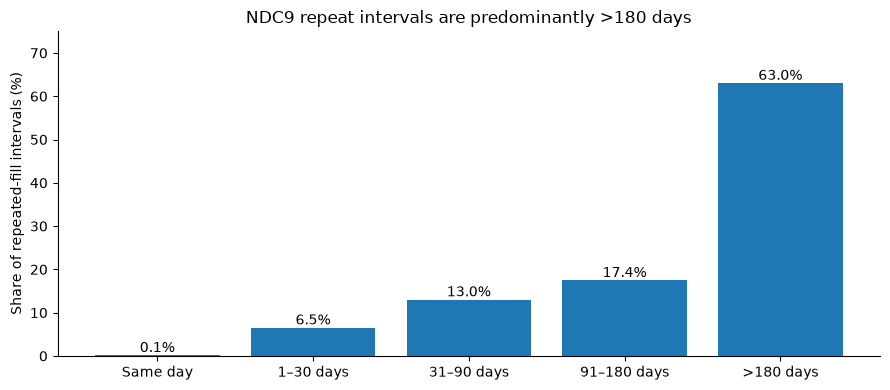

In [37]:
# Distribution of intervals between consecutive NDC9 events
row = df_refill_distribution.iloc[0]
labels = ["Same day", "1–30 days", "31–90 days", "91–180 days", ">180 days"]
counts = [
    row["same_day_pairs"],
    row["intervals_1_30_days"],
    row["intervals_31_90_days"],
    row["intervals_91_180_days"],
    row["intervals_over_180_days"],
]
total = sum(counts)
shares = [100 * value / total for value in counts]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, shares)
ax.set_ylabel("Share of repeated-fill intervals (%)")
ax.set_title("NDC9 repeat intervals are predominantly >180 days")
ax.set_ylim(0, max(shares) + 12)
for bar, share in zip(bars, shares):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
            f"{share:.1f}%", ha="center", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


**Finding — interval distribution:** Across **29,225** consecutive NDC9 pairs, **18,409 (63.0%)** were more than 180 days apart; **5,721 (19.6%)** were within 90 days, including same-day pairs.

In [38]:
sql_beneficiary_continuity = """
WITH prescription_history AS (
    SELECT
        desynpuf_id,
        ndc9_product_id,
        service_date,

        LAG(service_date) OVER (
            PARTITION BY desynpuf_id, ndc9_product_id
            ORDER BY service_date, source_row_id
        ) AS previous_fill_date

    FROM staging.prescription_drug_events_ndc9

    WHERE pdc_coverage_eligible IS TRUE
      AND ndc9_product_id IS NOT NULL
),

beneficiary_summary AS (
    SELECT
        desynpuf_id,

        COUNT(*) FILTER (
            WHERE previous_fill_date IS NOT NULL
        ) AS repeated_fill_pairs,

        COUNT(*) FILTER (
            WHERE service_date - previous_fill_date
                  BETWEEN 1 AND 90
        ) AS repeated_pairs_90d,

        COUNT(*) FILTER (
            WHERE service_date - previous_fill_date
                  BETWEEN 1 AND 180
        ) AS repeated_pairs_180d

    FROM prescription_history

    GROUP BY desynpuf_id
)

SELECT
    COUNT(*) AS total_beneficiaries,

    COUNT(*) FILTER (
        WHERE repeated_fill_pairs > 0
    ) AS beneficiaries_with_repeats,

    COUNT(*) FILTER (
        WHERE repeated_pairs_90d > 0
    ) AS beneficiaries_with_90d_repeats,

    COUNT(*) FILTER (
        WHERE repeated_pairs_180d > 0
    ) AS beneficiaries_with_180d_repeats

FROM beneficiary_summary;
"""

df_beneficiary_continuity = pd.read_sql(sql_beneficiary_continuity,
    engine
)

display(df_beneficiary_continuity)


,total_beneficiaries,beneficiaries_with_repeats,beneficiaries_with_90d_repeats,beneficiaries_with_180d_repeats
0,99393,20010,5194,9111


#### Findings — Beneficiary-Level Refill Continuity

I evaluated prescription continuity at the beneficiary
level to determine whether the dataset contained
sufficient longitudinal history for adherence modeling.

**Key findings:**

- 99,393 beneficiaries had usable prescription events.
- 20.1% had at least one repeated NDC9 prescription.
- 9.2% had a repeat within 180 days.
- Only 5.2% had a repeat within 90 days.

**Conclusion:**

Although NDC9 grouping improved the number of repeated
prescription sequences, relatively few beneficiaries
had repeated fills within shorter observation windows.

Combined with the limitations of the synthetic drug
identifiers, these results indicate that the dataset
alone cannot support clinically validated PDC labels
using our current grouping strategy.

I decided to preserve the CMS data for feature
engineering and use a separately identified simulated
adherence outcome if necessary for demonstrating the
supervised machine learning pipeline.


---
# 5. Feature engineering | Building the modeling dataset

**Objective:** Transform historical prescription activity into beneficiary-level features for predicting medication non-adherence.

I will use a 180-day observation window to engineer features related to prescription frequency, medication burden, refill timing, days supplied, and patient costs. I'll aggregate these features at the beneficiary level while ensuring that only information available before the prediction date is included to prevent data leakage.


## 5. Predictive Feature Engineering

### 5.1 Historical Prescription Features

I constructed a beneficiary-level feature dataset using
prescription events from the 180 days preceding
July 1, 2010.

The initial features capture:

- Prescription frequency
- Medication product diversity (NDC9)
- Average days supplied
- Average patient payment
- Number of zero-day supply events
- Days since the most recent prescription

All features are derived from records before the
prediction date to prevent future-data leakage.

NDC9 represents an exploratory product grouping,
not a validated therapeutic class.


In [39]:
# Section 5.1 — Historical prescription features

sql_patient_features_180d = """
WITH historical_prescriptions AS (
    SELECT
        desynpuf_id,
        ndc9_product_id,
        service_date,
        days_supply_reported,
        days_supply_is_zero,
        pdc_coverage_eligible,
        patient_pay_amount

    FROM staging.prescription_drug_events_ndc9

    WHERE service_date >= DATE '2010-07-01' - 180
      AND service_date < DATE '2010-07-01'
)

SELECT
    desynpuf_id,

    COUNT(*) AS total_prescriptions_180d,

    COUNT(DISTINCT ndc9_product_id)
        AS distinct_ndc9_180d,

    ROUND(
        AVG(days_supply_reported)
        FILTER (
            WHERE pdc_coverage_eligible IS TRUE
        ), 2
    ) AS avg_days_supply_180d,

    ROUND(
        AVG(patient_pay_amount), 2
    ) AS avg_patient_payment_180d,

    COUNT(*) FILTER (
        WHERE days_supply_is_zero IS TRUE
    ) AS zero_day_events_180d,

    DATE '2010-07-01' - MAX(service_date)
        AS days_since_last_fill,

    MIN(service_date) AS first_fill_180d,
    MAX(service_date) AS last_fill_180d

FROM historical_prescriptions

GROUP BY desynpuf_id

ORDER BY desynpuf_id;
"""

df_patient_features = pd.read_sql(
    sql_patient_features_180d,
    engine
)

print("Beneficiaries:", len(df_patient_features))
print("Dataset shape:", df_patient_features.shape)

display(df_patient_features.head(10))


Beneficiaries: 78720
Dataset shape: (78720, 9)


,desynpuf_id,total_prescriptions_180d,distinct_ndc9_180d,avg_days_supply_180d,avg_patient_payment_180d,zero_day_events_180d,days_since_last_fill,first_fill_180d,last_fill_180d
0,00013D2EFD8E45D1,34,34,38.24,11.18,0,23,2010-01-03,2010-06-08
1,00016F745862898F,4,4,30.00,2.50,1,19,2010-03-05,2010-06-12
2,0001FDD721E223DC,13,13,41.54,4.62,0,2,2010-01-10,2010-06-29
3,00021CA6FF03E670,4,4,45.00,0.00,0,6,2010-01-22,2010-06-25
4,00024B3D2352D2D0,1,1,30.00,10.00,0,151,2010-01-31,2010-01-31
5,0002DAE1C81CC70D,3,3,30.00,0.00,0,57,2010-03-15,2010-05-05
6,0002F28CE057345B,1,1,20.00,0.00,0,69,2010-04-23,2010-04-23
7,000308435E3E5B76,1,1,30.00,20.00,0,34,2010-05-28,2010-05-28
8,000345A39D4157C9,3,3,43.33,0.00,0,125,2010-01-19,2010-02-26
9,00036A21B65B0206,7,7,24.29,0.00,0,117,2010-01-05,2010-03-06
